# 04 · ¿Se seguirá vendiendo un artículo nuevo?

Predecir, con lo que se sabe en su **mes de estreno**, si un artículo nuevo
seguirá en el lineal seis meses después. Es un problema de **clasificación
supervisada** sobre 1.302 artículos estrenados entre enero de 2025 y enero de
2026.

## La conclusión, por delante

**Se puede, pero a medias, y conviene decirlo así.** La regresión logística
llega a un **AUC de 0,705** frente al 0,5 del azar: hay señal real, pero no es
un clasificador fuerte. Donde sí es útil de verdad es **en el extremo malo**:
de los 130 artículos que peor puntúa, solo sigue en el lineal el **4,6 %**,
frente al 40,2 % de partida. Predecir el fracaso sale mucho mejor que predecir
el éxito, y para decidir qué no reponer es justo lo que hace falta.

**«Seguir vendiéndose» se mide con la regla de la propia tienda:** un artículo
que pasa **tres meses seguidos sin venderse** se retira del lineal. Sigue a los
6 meses el artículo al que esa regla no le ha saltado en sus 6 primeros meses.

**Se mide a 6 meses y no a 12** porque es el plazo que importa para decidir la
reposición, y porque a 12 meses el grupo de artículos solo cubriría estrenos de
enero a julio; a 6 meses cubre los 12 meses del año.

**Ampliaciones:**
- **Sección 10:** no solo *si* se sigue vendiendo, sino *cuánto* —unidades y
  venta aproximadas en los primeros 6 meses—, con Binomial Negativa y un modelo
  log-lineal.
- **Sección 12:** un **árbol de supervivencia** que no dice solo si el artículo
  sigue a los 6 meses, sino *cómo va cayendo* mes a mes, y que aprovecha
  también los artículos cuya historia no ha terminado.

## Técnicas

| Pieza | Técnica |
|---|---|
| Referencia | `DummyClassifier` (clase mayoritaria) |
| Modelo principal | Regresión logística (`glm` binomial) |
| Modelo interpretable | Árbol de clasificación (CART) |
| Evaluación | Curva ROC, AUC y curva *lift* |
| Validación | Validación cruzada estratificada de 5 pliegues |
| Volumen de venta (sección 10) | Poisson, Binomial Negativa y log-lineal |
| Supervivencia (sección 12) | Kaplan-Meier, árbol de supervivencia e índice C |

In [1]:
import sys

sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_curve

import supervivencia as sv

GUARDAR_FIGURAS = True
FIGURAS = Path("../reports/figuras")

# Misma paleta y mismo helper de formato que los notebooks 01, 02 y 03.
AZUL, NARANJA, AQUA, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"
TINTA, TINTA2, REJILLA, GRIS = "#0b0b0b", "#52514e", "#e1e0d9", "#8a8983"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2,
    "text.color": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "grid.color": REJILLA, "axes.grid": True, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})


def num(valor, dec=2, signo=False):
    """Convención española: 5.355,29. Mismo helper que los notebooks 01-03."""
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "—"
    crudo = f"{valor:{'+' if signo else ''},.{dec}f}"
    return crudo.replace(",", "\x00").replace(".", ",").replace("\x00", ".")


pd.options.display.float_format = num


def guardar(fig, nombre):
    if not GUARDAR_FIGURAS:
        return
    FIGURAS.mkdir(parents=True, exist_ok=True)
    base = FIGURAS / f"04-{nombre}"
    fig.savefig(base.with_suffix(".png"), dpi=150, bbox_inches="tight")
    fig.savefig(base.with_suffix(".svg"), bbox_inches="tight")
    print(f"  guardada {base.name}.png / .svg")

## 1 · El grupo de artículos nuevos, y el censurado que lo define

**Es la decisión metodológica de todo el notebook, y va antes que ningún
modelo.**

El panel llega hasta **julio de 2026**. Un artículo que debutó en marzo de
2026 no ha tenido tiempo de cumplir 6 meses: **no es que se haya dejado de
vender, es que todavía no se sabe**. Contarlo como fracaso hundiría
artificialmente la tasa base, y el modelo aprendería a predecir *la fecha de
estreno*, no si el artículo se sigue vendiendo.

Por eso el grupo son solo los estrenos **de enero de 2025 a enero de 2026**:
los únicos con 6 meses de seguimiento posible dentro de los datos. El límite
inferior se mantiene aunque el panel empiece en enero de 2024, porque un
artículo «visto por primera vez» al principio del panel pudo existir antes: se
exige un año entero de panel antes de confiar en que un estreno es real.

**Qué es «seguir vendiéndose»: la regla de retirada de la tienda.** Un
artículo que pasa **tres meses seguidos sin venderse** se lleva a la zona de
caja con pegatina amarilla y se retira del lineal. La etiqueta es **sí** si
esa regla no ha saltado en los 6 primeros meses del artículo. Como todos los
artículos del grupo tienen al menos 6 meses observados, la etiqueta se conoce
en todos.

> Una primera versión daba por bueno que el artículo volviera a aparecer en el
> mes 6, aunque entretanto hubiera pasado tres meses o más sin vender. Se
> cambió porque la tienda lo habría retirado igual; la sección 12 mide la
> diferencia.

In [2]:
d = sv.construir_grupo_articulos_nuevos()

panel = sv.cargar_panel()
estreno_todos = panel.groupby("cod_articulo")["mes"].min()
desde_2025 = ((estreno_todos >= pd.Period("2025-01")) & (estreno_todos <= panel["mes"].max())).sum()

print(f"Artículos del panel entero ................ {panel['cod_articulo'].nunique():,}")
print(f"Estrenados desde enero de 2025 hasta el fin del panel {desde_2025:,}")
print(f"  de ellos, con {sv.MESES_SUPERVIVENCIA} meses de seguimiento ... {len(d):,}   <- El grupo")
print(f"  descartados por censura ................. {desde_2025 - len(d):,}")
print()
print(f"Se siguen vendiendo a los {sv.MESES_SUPERVIVENCIA} meses ..............."
      f" {int(d['sobrevive'].sum()):,}  ({num(100 * d['sobrevive'].mean(), 1)} %)")
print()
print()
print("Meses de estreno cubiertos por el grupo:", sorted(d["mes_estreno"].unique()))

Artículos del panel entero ................ 6,696
Estrenados desde enero de 2025 hasta el fin del panel 1,728
  de ellos, con 6 meses de seguimiento ... 1,302   <- El grupo
  descartados por censura ................. 426

Se siguen vendiendo a los 6 meses ............... 524  (40,2 %)


Meses de estreno cubiertos por el grupo: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


La tasa base es 40,2 %, y eso decide el marco de evaluación.
El marco habitual aquí es 'clasificación con datos no balanceados', pero
esta partición no es un desbalanceo severo: aplicar remuestreo o rose
aquí sería un error metodológico. Se usa ROC, AUC y
lift sin la corrección, que es lo que el dato pide.

El grupo cubre estrenos de los 12 meses del año, no solo de enero-julio como pasaba con el umbral de 12 meses.
Es lo que evita que `mes_estreno` se use luego para extrapolar fuera de
lo observado (agosto-diciembre).

## 2 · Dónde se deja de vender el surtido — el descriptivo que ya vale por sí solo

Antes de modelar, la tabla que la tienda entendería sin más explicación.

,articulos,siguen_vendiendose,tasa_pct
departamento,,,
CHARCUTERIA L.S,22,13,"59,10"
DEPARTAMENTO NO ESPECIFICADO,46,26,"56,50"
DROGUERIA Y PERFUMERIA,223,117,"52,50"
ULTRAMARINOS,469,232,"49,50"
BEBIDAS,83,36,"43,40"
LACTEOS,57,22,"38,60"
CHARCUTERIA CORTE,52,18,"34,60"
CONGELADOS,88,24,"27,30"
FRUTAS Y VERDURAS,58,15,"25,90"


  guardada 04-supervivencia-por-departamento.png / .svg


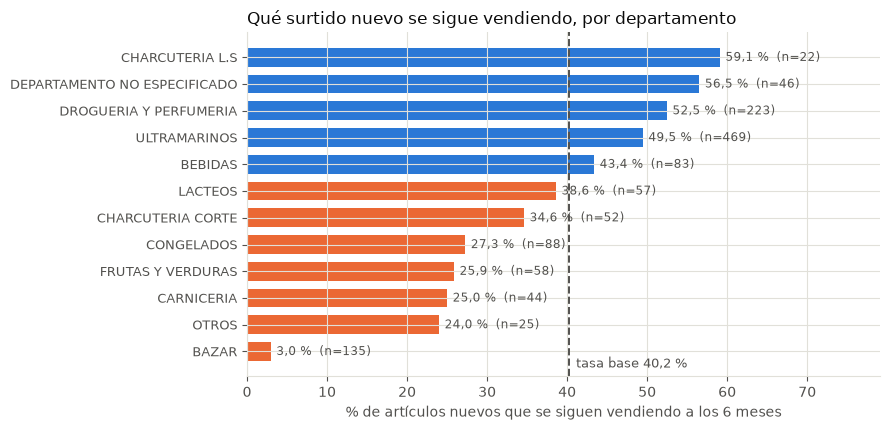

In [3]:
por_dpto = (d.groupby("departamento")["sobrevive"]
            .agg(articulos="size", siguen_vendiendose="sum", tasa="mean")
            .sort_values("tasa", ascending=False))
por_dpto["tasa_pct"] = 100 * por_dpto["tasa"]
display(por_dpto[["articulos", "siguen_vendiendose", "tasa_pct"]].round(1))

base = d["sobrevive"].mean()
mejor, peor = por_dpto.index[0], por_dpto.index[-1]

fig, ax = plt.subplots(figsize=(9, 4.4))
colores = [NARANJA if t < base else AZUL for t in por_dpto["tasa"]]
ax.barh(range(len(por_dpto)), 100 * por_dpto["tasa"], color=colores, height=0.7)
ax.set_yticks(range(len(por_dpto)), por_dpto.index, fontsize=9)
ax.invert_yaxis()
ax.axvline(100 * base, color=TINTA2, linestyle="--", linewidth=1.4)
ax.annotate(f"tasa base {num(100 * base, 1)} %",
            xy=(100 * base, len(por_dpto) - 0.4), xytext=(5, 0),
            textcoords="offset points", fontsize=9, color=TINTA2)
for i, (n, t) in enumerate(zip(por_dpto["articulos"], por_dpto["tasa"])):
    ax.annotate(f"{num(100 * t, 1)} %  (n={n})", xy=(100 * t, i), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=TINTA2)
ax.set_xlabel(f"% de artículos nuevos que se siguen vendiendo a los {sv.MESES_SUPERVIVENCIA} meses")
ax.set_xlim(0, min(100, 100 * por_dpto["tasa"].max() + 20))
ax.set_title("Qué surtido nuevo se sigue vendiendo, por departamento",
             loc="left", fontsize=12, color=TINTA)
fig.tight_layout()
guardar(fig, "supervivencia-por-departamento")
plt.show()

El rango es enorme, y ese es el hallazgo de la sección.
En bazar se sigue vendiendo solo el 3,0 %
En charcuteria L.S se sigue vendiendo el 59,1 %
En el mejor departamento se sigue vendiendo 19,9 veces más que en el peor.
Un artículo nuevo de bazar es casi siempre una compra
puntual que no se repone; uno de droguería entra en el surtido fijo.
Esto no necesita ningún modelo para ser útil.

## 3 · Los predictores, y la regla que hace válido el ejercicio

**Ninguna variable mira más allá del mes de estreno.** Si se usara la venta
del mes 3 para predecir si el artículo sigue en el mes 6, el modelo acertaría
casi siempre y no serviría para nada: cuando la tienda decide si sigue con un
artículo, solo sabe cómo entró.

| Variable | Qué es |
|---|---|
| `unidades`, `venta`, `precio` | Cómo arrancó, en su primer mes |
| `margen_unit` | Precio − `tarifa_costo`, **en euros y no en %** |
| `oferta` | Marca de oferta en el mes de estreno |
| `prefijo_promo` | La descripción empieza por `(P)`, promoción de la central |
| `mes_estreno` | Mes del año en que entró |
| `departamento` | 11 niveles + `OTROS` |

> **Por qué el margen va en euros.** El porcentaje de rentabilidad llega a
> **452.984 %** cuando el coste registrado es casi cero, y esa cola rompe
> cualquier modelo lineal. La diferencia precio − coste está acotada y se
> entiende sola. La sección 8 comprueba además si el resultado depende de las
> variables de coste.

In [4]:
X, y = sv.matriz(d)
print(f"Matriz de diseño: {X.shape[0]} artículos x {X.shape[1]} variables\n")
display(d[["unidades", "precio", "venta", "margen_unit"]].describe().round(2))

neg = d[(d["unidades"] < 0) | (d["venta"] < 0)]
sin_precio = d[d["precio"] == 0]

print("\nVariables binarias:")
for c in ["oferta", "prefijo_promo"]:
    print(f"  {c:15} {int(d[c].sum()):3d} artículos ({num(100 * d[c].mean(), 1)} %)")

Matriz de diseño: 1302 artículos x 18 variables



,unidades,precio,venta,margen_unit
count,"1.302,00","1.302,00","1.302,00","1.302,00"
mean,"4,93","3,54","11,46","0,90"
std,"16,82","4,32","19,63","1,02"
min,"-4,00","0,00","-7,27","-3,95"
25%,"1,00","1,49","2,99","0,33"
50%,"2,00","2,31","5,92","0,59"
75%,"5,00","3,59","12,49","0,99"
max,"504,00","71,82","217,71","9,05"



Variables binarias:
  oferta          142 artículos (10,9 %)
  prefijo_promo   153 artículos (11,8 %)


El mínimo de 'unidades'/'venta' es negativo, y hay que decir por qué:
2 artículos entran con unidades y venta negativas en su propio
mes de alta — una devolución sin venta positiva que la compense ese
mismo mes (chorizo casero extra, piponazo maxi 180G). No es un error de datos:
son facturas rectificativas.

Y 8 artículos entran con precio = 0:
unidades y venta se cancelan exactamente en el mes de estreno (una
devolución igual a la venta), así que el precio medio del mes,
venta / unidades, queda indefinido y el parser lo deja en 0. Dos de
ellos —ginebra bombay 70 cl y cordon blue jamon-— son los mismos que
en la sección 10 tienen unidades_ventana = 0, por el mismo motivo.
Ninguno se excluye: son el propio mes de estreno tal cual lo registra
el TPV, y el modelo los ve igual que a cualquier otro.

## 4 · Los tres modelos

Validación cruzada **estratificada** de 5 pliegues: con una tasa base del
40,2 %, un pliegue aleatorio podría quedarse con una proporción muy distinta y
las métricas dejarían de ser comparables.

Las probabilidades con las que se construyen la ROC y el *lift* son **fuera de
muestra**: cada artículo lo puntúa el pliegue que no lo vio.

In [5]:
tabla, probas = sv.evaluar(X, y)
display(tabla.round(3))

auc_log = tabla.loc["logistica", "auc"]
auc_arb = tabla.loc["arbol", "auc"]

,procedencia,auc,acierto,lift_decil_1
modelo,,,,
baseline,DummyClassifier,"0,50","0,60","1,16"
logistica,regresión logística,"0,70","0,65","1,50"
arbol,CART,"0,63","0,62","1,48"


Dos lecturas.

1. Hay señal, pero no es un clasificador fuerte. La logística da
AUC 0,705 contra el 0,498
del listón, que es el azar. Es una mejora real y medible, pero muy
lejos de un modelo que decida solo: hay que reportarlo así.

2. El árbol pierde (0,627), y es lo esperable con
profundidad 3. Se poda a propósito: se buscan modelos
interpretables, y un CART de 3 niveles cabe en una figura que la
tienda lee. Un árbol sin podar acertaría algo más y no lo leería nadie.

## 5 · La curva ROC

La ROC recorre todos los puntos de corte posibles en vez de fijar uno: por eso
el AUC no depende del umbral, al contrario que el porcentaje de acierto.

  guardada 04-roc-supervivencia.png / .svg


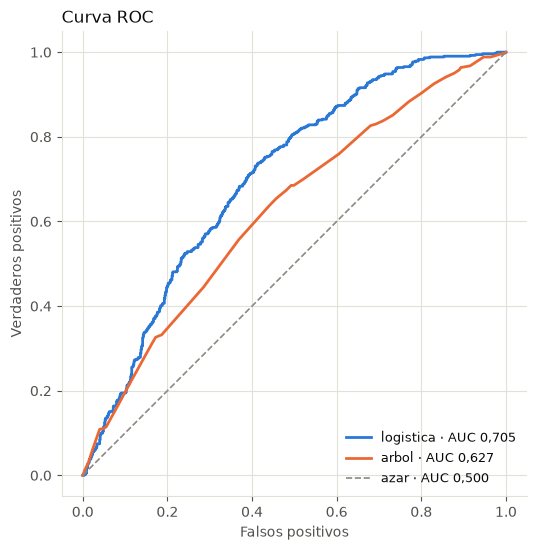

In [6]:
fig, ax = plt.subplots(figsize=(5.6, 5.6))

for nombre, color in [("logistica", AZUL), ("arbol", NARANJA)]:
    fpr, tpr, _ = roc_curve(y, probas[nombre])
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f"{nombre} · AUC {num(tabla.loc[nombre, 'auc'], 3)}")

ax.plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1.2,
        label="azar · AUC 0,500")
ax.set_xlabel("Falsos positivos")
ax.set_ylabel("Verdaderos positivos")
ax.set_title("Curva ROC", loc="left", fontsize=12, color=TINTA)
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_aspect("equal")
fig.tight_layout()
guardar(fig, "roc-supervivencia")
plt.show()

El AUC se lee como una probabilidad: tomado un artículo que se
sigue vendiendo y otro que no, el modelo puntúa más alto al que se
sigue vendiendo el 70,5 % de las veces. El azar
acertaría el 50 %.

## 6 · El *lift*: la lectura que entiende la tienda

No dice *«el AUC es 0,70»* sino *«de los 130 artículos que el modelo pone
abajo, solo 6 siguen en el lineal a los 6 meses»*.

,n,sobreviven,tasa,lift,acumulado_capturado
decil,,,,,
1,131,79,"0,60","1,50","0,15"
2,131,76,"0,58","1,44","0,30"
3,130,80,"0,61","1,53","0,45"
4,130,62,"0,48","1,19","0,57"
5,130,61,"0,47","1,17","0,68"
6,130,51,"0,39","0,97","0,78"
7,130,42,"0,32","0,80","0,86"
8,130,43,"0,33","0,82","0,94"
9,130,24,"0,18","0,46","0,99"


  guardada 04-lift-supervivencia.png / .svg


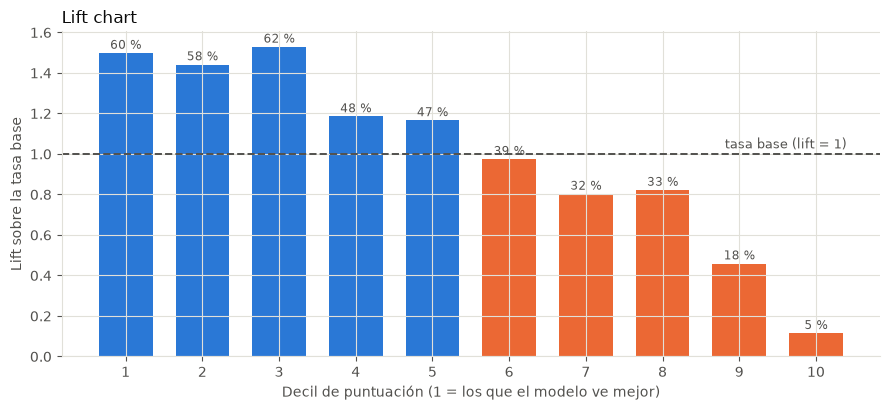


   Decil 1  (los 131 mejor puntuados): se sigue vendiendo el 60,3 %  ->  lift 1,50
   Decil 10 (los 130 peor puntuados):  se sigue vendiendo el 4,6 %  ->  lift 0,11


In [7]:
lift = sv.curva_lift(y, probas["logistica"])
display(lift.round(3))

fig, ax = plt.subplots(figsize=(9, 4.2))
colores = [AZUL if v >= 1 else NARANJA for v in lift["lift"]]
ax.bar(lift.index, lift["lift"], color=colores, width=0.7)
ax.axhline(1, color=TINTA2, linestyle="--", linewidth=1.4)
ax.annotate("tasa base (lift = 1)", xy=(10.4, 1), xytext=(0, 4),
            textcoords="offset points", ha="right", fontsize=9, color=TINTA2)
for i, (v, t) in enumerate(zip(lift["lift"], lift["tasa"]), start=1):
    ax.annotate(f"{num(100 * t, 0)} %", xy=(i, v), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8.5, color=TINTA2)
ax.set_xticks(lift.index)
ax.set_xlabel("Decil de puntuación (1 = los que el modelo ve mejor)")
ax.set_ylabel("Lift sobre la tasa base")
ax.set_title("Lift chart", loc="left", fontsize=12, color=TINTA)
fig.tight_layout()
guardar(fig, "lift-supervivencia")
plt.show()

d1, d10 = lift.loc[1], lift.loc[10]
base_pct = 100 * d["sobrevive"].mean()
print()
print(f"   Decil 1  (los {int(d1['n'])} mejor puntuados): se sigue vendiendo el "
      f"{num(100 * d1['tasa'], 1)} %  ->  lift {num(d1['lift'], 2)}")
print(f"   Decil 10 (los {int(d10['n'])} peor puntuados):  se sigue vendiendo el "
      f"{num(100 * d10['tasa'], 1)} %  ->  lift {num(d10['lift'], 2)}")

Arriba mejora algo: del 40 % al 60 %. Abajo el resultado
es rotundo: del 40 % al 5 %. En términos de negocio, el
modelo ayuda poco a decidir en qué artículo nuevo apostar (4 de cada 10
de sus favoritos se retiran igual), y sí sirve para señalar cuáles casi
seguro no hay que reponer. 

El modelo sirve mucho mejor para descartar que para apostar.

## 7 · Por qué decide lo que decide

Dos formas de interpretar el resultado: los **odds ratio** de la logística y
el **árbol dibujado**.

In [8]:
coef = sv.coeficientes_logistica(X, y)
display(coef.round(3))

or_ultramarinos = num(coef.loc["dpto_ULTRAMARINOS", "odds_ratio"], 2)

,coef,odds_ratio
dpto_ULTRAMARINOS,"1,47","4,34"
dpto_DROGUERIA Y PERFUMERIA,"1,25","3,48"
dpto_BEBIDAS,"0,75","2,12"
dpto_DEPARTAMENTO NO ESPECIFICADO,"0,62","1,85"
dpto_LACTEOS,"0,54","1,71"
dpto_CONGELADOS,"0,51","1,67"
dpto_CHARCUTERIA L.S,"0,49","1,63"
dpto_CHARCUTERIA CORTE,"0,48","1,62"
dpto_CARNICERIA,"0,45","1,56"
dpto_FRUTAS Y VERDURAS,"0,37","1,45"


Se leen así: subir la variable una desviación típica multiplica por
`odds_ratio` las probabilidades a favor de que el artículo se siga
vendiendo. Mayor que 1 ayuda.

Los `dpto_*` se leen frente a bazar, que es la referencia que queda fuera
de la tabla (la primera por orden alfabético, y también el departamento
donde menos se sigue vendiendo — sección 2): 'dpto_ULTRAMARINOS = 4,35'
significa 4,35 veces más ventaja de seguir vendiéndose que un
artículo de bazar, no que ultramarinos sea esas veces mejor que la media
de la tienda.

  guardada 04-arbol-supervivencia.png / .svg


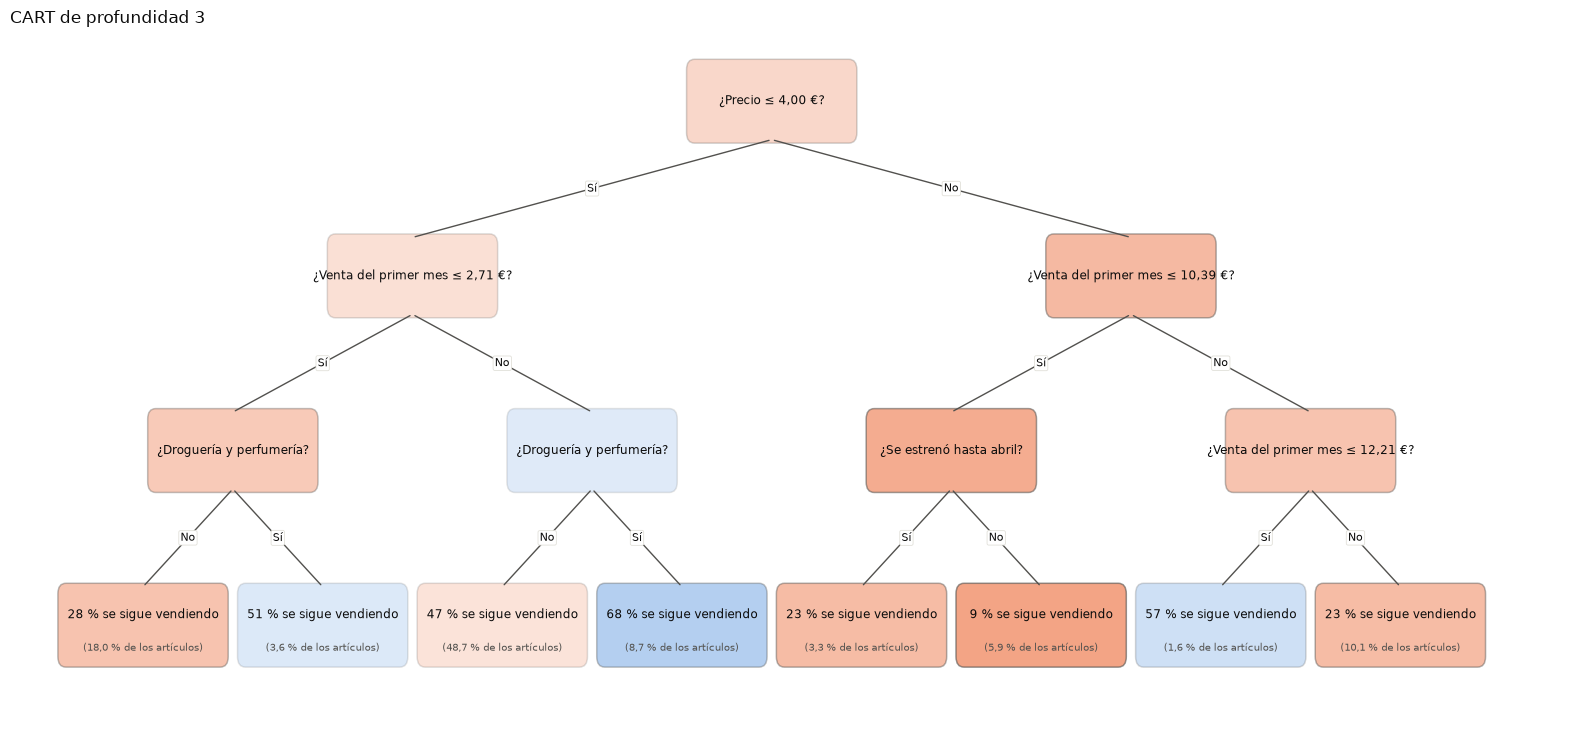

In [9]:
import matplotlib.patches as mpatches
from sklearn.tree._tree import TREE_LEAF

# Mismo estimador que sv.construir_modelos()["arbol"] (sección 4), no una copia
# de sus hiperparámetros: si `profundidad_arbol` cambiara ahí, esta figura lo
# seguiría sin tocar nada aquí.
arbol = sv.construir_modelos()["arbol"][0].fit(X, y)

# El árbol y sus cifras (el AUC de la sección 4) son los mismos que da
# `plot_tree()` de sklearn - aquí se dibujan a mano en vez de con esa función,
# por dos motivos que `plot_tree` no resuelve bien para una figura pensada para
# la tienda: (1) solo rotula "Sí/No" en la primera pregunta, no en las demás -
# hay que inferir el resto; (2) cada caja mezcla el % de artículos, la
# proporción cruda y la clase, cuando lo único que importa en un tramo final es
# el % de que el artículo se siga vendiendo.
t = arbol.tree_
NOMBRES_AMIGABLES = {
    "dpto_DROGUERIA Y PERFUMERIA": "Droguería y perfumería",
    "dpto_ULTRAMARINOS": "Ultramarinos",
    "dpto_CONGELADOS": "Congelados",
    "dpto_BEBIDAS": "Bebidas",
    "dpto_LACTEOS": "Lácteos",
    "dpto_CARNICERIA": "Carnicería",
    "dpto_CHARCUTERIA CORTE": "Charcutería corte",
    "dpto_CHARCUTERIA L.S": "Charcutería L.S",
    "dpto_FRUTAS Y VERDURAS": "Frutas y verduras",
    "dpto_DEPARTAMENTO NO ESPECIFICADO": "Departamento no especificado",
    "dpto_OTROS": "Otro departamento pequeño",
    "precio": "Precio",
    "venta": "Venta del primer mes",
    "margen_unit": "Margen unitario",
    "mes_estreno": "Mes de estreno",
    "unidades": "Unidades del primer mes",
    "oferta": "Oferta",
    "prefijo_promo": "Promoción central",
}
VARIABLES_SI_NO = {c for c in X.columns if c.startswith("dpto_")} | {"oferta", "prefijo_promo"}
MESES_NOMBRE = ["", "enero", "febrero", "marzo", "abril", "mayo", "junio", "julio",
                "agosto", "septiembre", "octubre", "noviembre", "diciembre"]


def es_hoja(nid):
    return t.children_left[nid] == TREE_LEAF


def pregunta_y_etiquetas(nid):
    """Texto de la pregunta del nodo, y qué contesta cada rama (Sí/No).

    Cuidado: no siempre es "izquierda=No, derecha=Sí": para una variable de
    departamento (0/1) la condición interna es "¿no es de tal departamento?",
    así que la izquierda (condición cierta) es "No". Para un umbral
   (precio ≤ X) la condición es literalmente la pregunta, así que la
    izquierda (condición cierta) es "Sí".
    """
    variable = X.columns[t.feature[nid]]
    umbral = t.threshold[nid]
    nombre = NOMBRES_AMIGABLES.get(variable, variable)
    if variable in VARIABLES_SI_NO:
        return f"¿{nombre}?", "No", "Sí"
    if variable == "mes_estreno":
        return f"¿Se estrenó hasta {MESES_NOMBRE[int(umbral)]}?", "Sí", "No"
    if variable in ("precio", "venta", "margen_unit"):
        return f"¿{nombre} ≤ {num(umbral, 2)} €?", "Sí", "No"
    return f"¿{nombre} ≤ {num(umbral, 2)}?", "Sí", "No"


# Layout: las hojas se reparten en el eje X de izquierda a derecha, y cada nodo
# interno se coloca en la media de sus dos hijos - sencillo porque este árbol
# es binario completo de profundidad 3 (15 nodos, sin ramas cortadas).
posiciones, profundidad = {}, {}
_contador = [0]


def _asignar(nid, prof):
    profundidad[nid] = prof
    if es_hoja(nid):
        x = _contador[0]
        _contador[0] += 1
        posiciones[nid] = x
        return x
    xi = _asignar(t.children_left[nid], prof + 1)
    xd = _asignar(t.children_right[nid], prof + 1)
    posiciones[nid] = (xi + xd) / 2
    return posiciones[nid]


_asignar(0, 0)

ESPACIO_X = 1.35
n_articulos_total = t.n_node_samples[0]

fig, ax = plt.subplots(figsize=(16, 7.5))
for nid, xg in posiciones.items():
    x, ypix = xg * ESPACIO_X, -profundidad[nid]
    valores = t.value[nid][0]
    prob_sigue = valores[1] / valores.sum()
    pct_articulos = 100 * t.n_node_samples[nid] / n_articulos_total
    intensidad = 0.15 + 0.55 * abs(prob_sigue - 0.5) * 2
    color = AZUL if prob_sigue >= 0.5 else NARANJA

    caja = mpatches.FancyBboxPatch(
        (x - 0.62, ypix - 0.22), 1.24, 0.44,
        boxstyle="round,pad=0.02,rounding_size=0.06",
        linewidth=1.1, edgecolor=TINTA2, facecolor=color, alpha=intensidad, zorder=2)
    ax.add_patch(caja)

    if es_hoja(nid):
        ax.text(x, ypix + 0.06, f"{num(100 * prob_sigue, 0)} % se sigue vendiendo",
                ha="center", va="center", fontsize=8.5, color=TINTA, zorder=3)
        ax.text(x, ypix - 0.13, f"({num(pct_articulos, 1)} % de los artículos)",
                ha="center", va="center", fontsize=7, color=TINTA2, zorder=3)
    else:
        pregunta, _, _ = pregunta_y_etiquetas(nid)
        ax.text(x, ypix, pregunta, ha="center", va="center", fontsize=8.5,
                color=TINTA, zorder=3)

    if nid != 0:
        padre = next(p for p in posiciones
                     if t.children_left[p] == nid or t.children_right[p] == nid)
        xp, yp = posiciones[padre] * ESPACIO_X, -profundidad[padre]
        es_izquierda = t.children_left[padre] == nid
        _, etiqueta_izq, etiqueta_der = pregunta_y_etiquetas(padre)
        etiqueta = etiqueta_izq if es_izquierda else etiqueta_der
        ax.annotate("", xy=(x, ypix + 0.22), xytext=(xp, yp - 0.22),
                    arrowprops=dict(arrowstyle="-", color=TINTA2, linewidth=1))
        ax.text((x + xp) / 2, (ypix + yp) / 2, etiqueta, ha="center", va="center",
                fontsize=8, color=TINTA,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=REJILLA, lw=0.6))

ax.set_xlim(-1, _contador[0] * ESPACIO_X)
ax.set_ylim(-3.6, 0.4)
ax.axis("off")
ax.set_title("CART de profundidad 3", loc="left", fontsize=12, color=TINTA)
fig.tight_layout()
guardar(fig, "arbol-supervivencia")
plt.show()

El árbol es la figura para la tienda: se lee sin saber estadística.
Cada pregunta tiene su propio 'Sí' y 'No' en la rama que le
corresponde, y las cajas finales solo dicen qué % de esos
artículos se sigue vendiendo — cada rama es una regla que la
tienda puede aplicar a mano.

### Qué mide exactamente este árbol

Dado un artículo, y contestando 3 preguntas sobre él (precio, cuánto facturó
en su primer mes, departamento o mes de lanzamiento, según la rama), la caja
final dice **qué porcentaje de los 1.302 artículos parecidos seguía en el
lineal 6 meses después de su estreno**.

- **Contesta una pregunta fija**: «¿se sigue vendiendo a los 6 meses?». Para
  otro plazo habría que volver a entrenar el árbol.
- **Da un porcentaje histórico, no una certeza**: «68 % se sigue vendiendo»
  significa que de los artículos que contestaron igual esas preguntas, el 68 %
  seguía en el lineal.
- **No dice cómo se llega a los 6 meses**: un artículo que se retira en el mes
  3 y otro que aguanta hasta el 5 cuentan igual. Eso lo añade el árbol de
  supervivencia de la sección 12.

**Un matiz para un producto que todavía no existe.** Tres de las preguntas
piden **la venta del primer mes**, el total facturado en el mes de estreno, que
un producto sin lanzar no tiene. Para ese caso está la herramienta del final
del notebook (`sv.predecir_producto_nuevo()`): usa la logística, más precisa
(AUC 0,705 frente al 0,627 de este árbol), y si no se le da la venta del
primer mes, **la estima** con el modelo de la sección 10.

## 8 · Tres objeciones, medidas

Tres preguntas que cualquiera haría al ver el modelo, contestadas con datos.

In [10]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(n_splits=sv.N_PLIEGUES, shuffle=True, random_state=sv.SEMILLA)


def auc_de(Xp):
    """AUC de la misma logistica de la seccion 4, cambiando solo las columnas.

    Se reutiliza `sv.construir_modelos()` en vez de instanciar una
    `LogisticRegression` suelta: sin el `StandardScaler` del pipeline el AUC
    sale distinto, y la tabla compararía contra un modelo distinto del que se
    ha reportado arriba.
    """
    modelo = sv.construir_modelos()["logistica"][0]
    p = cross_val_predict(modelo, Xp, y, cv=cv, method="predict_proba")[:, 1]
    return roc_auc_score(y, p)


solo_dpto = X[[c for c in X.columns if c.startswith("dpto_")]]
sin_dpto = X[[c for c in X.columns if not c.startswith("dpto_")]]
X_sin_coste, _ = sv.matriz(d, con_coste=False)

comp = pd.DataFrame(
    {"auc": [auc_de(solo_dpto), auc_de(sin_dpto), auc_de(X), auc_de(X_sin_coste)]},
    index=["solo departamento", "sin departamento", "todo (el modelo)",
           "sin las variables de coste"])
display(comp.round(3))

p_log = probas["logistica"].to_numpy()
n_decil = len(d) // 10
peor_decil = d["departamento"].to_numpy()[np.argsort(-p_log)][-n_decil:]
print(f"Composición del decil 10 (los {n_decil} peor puntuados):")
print(pd.Series(peor_decil).value_counts().to_string())

,auc
solo departamento,"0,66"
sin departamento,"0,58"
todo (el modelo),"0,70"
sin las variables de coste,"0,70"


Composición del decil 10 (los 130 peor puntuados):
BAZAR                118
ULTRAMARINOS           4
CARNICERIA             2
BEBIDAS                2
CHARCUTERIA CORTE      2
CONGELADOS             1
OTROS                  1


In [11]:
print()
print(f"   solo departamento .. AUC {num(comp.loc['solo departamento', 'auc'], 3)}")
print(f"   sin departamento ... AUC {num(comp.loc['sin departamento', 'auc'], 3)}")
print(f"   los dos juntos ..... AUC {num(comp.loc['todo (el modelo)', 'auc'], 3)}")
print()
print()
print()
print(f"   con variables de coste ... AUC {num(comp.loc['todo (el modelo)', 'auc'], 3)}")
print(f"   sin variables de coste ... AUC {num(comp.loc['sin las variables de coste', 'auc'], 3)}")
brecha = comp.loc["todo (el modelo)", "auc"] - comp.loc["sin las variables de coste", "auc"]


   solo departamento .. AUC 0,657
   sin departamento ... AUC 0,585
   los dos juntos ..... AUC 0,705



   con variables de coste ... AUC 0,705
   sin variables de coste ... AUC 0,702


Cada bloque por separado rinde bastante menos y juntos suben: la
información es complementaria, no redundante. Matiz: el decil
10 sí es en su mayoría bazar, así que la predicción extrema sí la
manda el departamento. Lo que el resto de variables aportan es el
orden dentro.

Diferencia: 3 milésimas de AUC.
La base de coste no condiciona el resultado: el modelo ordena casi igual
los artículos con las variables de coste y sin ellas.

Objeción 1: «esto es solo mirar el departamento». No, y está medido.

Objeción 2: «el margen depende de la base de coste».

### Objeción 3: «¿y por qué 3 meses?»

Porque es la regla de la propia tienda. Pero hay que comprobar que las
conclusiones **no dependen de ese número**: se rehace todo —grupo, etiqueta y
evaluación— con reglas de **2 y 4 meses** seguidos sin venta.

**Lo que NO se compara es la tasa base.** Con una regla más blanda sobreviven
más artículos por pura definición: el producto es el mismo, cambia la vara de
medir. Lo que se mira es si el modelo **concluye lo mismo**: si separa igual
(AUC, decil 10), si los extremos por departamento son los mismos, si el árbol
empieza por la misma pregunta y si ordena los artículos igual (correlación de
rangos de Spearman con las puntuaciones de la regla de 3 meses, sobre los
mismos artículos). Una regla de 6 meses no se prueba: con un horizonte de 6,
casi no podría saltar dentro de él.

In [12]:
robustez = sv.robustez_umbral((2, 3, 4))
display(robustez.T)

r = robustez

meses_sin_venta,2,3,4
tasa_base,"0,30","0,40","0,51"
auc,"0,70","0,70","0,69"
auc_arbol,"0,64","0,63","0,63"
decil1,"0,44","0,60","0,72"
decil10,"0,02","0,05","0,06"
peor_dpto,BAZAR,BAZAR,BAZAR
peor_tasa,"0,01","0,03","0,06"
mejor_dpto,DEPARTAMENTO NO ESPECIFICADO,CHARCUTERIA L.S,CHARCUTERIA L.S
mejor_tasa,"0,43","0,59","0,68"
mejor_n,46,22,22


Las conclusiones no dependen de que la regla sea de 3 meses.

- El modelo separa igual: AUC de 0,692 a 0,705 con las tres reglas.
- El peor departamento es siempre bazar.
- El árbol empieza siempre por el precio: precio ≤ 3.92, precio ≤ 4.00, precio ≤ 4.00.
- Ordena los artículos casi igual: Spearman con la regla de 3 meses de 0,91 a 0,93.

Lo que sí cambia es la tasa base (del 30 % al 51 %), y eso es la definición, no
el producto. Y el mejor departamento varía entre departamentos pequeños
(de 22 a 46 estrenos): la cabeza de la tabla es menos firme que la cola.

## 9 · Decisiones de diseño

**No se corrige el desbalanceo (ni remuestreo ni `ROSE`).** Con una tasa base
del **40,2 %** no hay un desbalanceo severo que corregir, y aplicar la
corrección sin necesidad sería un error metodológico. Se usan las métricas
pensadas para clases desbalanceadas (ROC, AUC, *lift*), no su corrección.

**No se usan Random Forest ni SVM.** Subirían algo el AUC, pero se perdería la
lectura de negocio: con la logística y el árbol se puede explicar a la tienda
*por qué* un artículo puntúa bajo.

**Si el AUC de 0,705 se queda corto**, el camino no es un modelo más potente
sino **más variables del estreno**: hoy son seis, y se podría añadir el
historial del proveedor o la familia comercial.

## 10 · Ampliación: ¿cuánto va a vender?

La logística contesta sí o no. Esto contesta *«y si se sigue vendiendo,
¿cuánto, aproximadamente?»*, sobre el **mismo grupo** de 1.302 estrenos,
porque la censura que garantiza 6 meses de seguimiento es la misma que hace
falta aquí: **el objetivo es la suma de unidades (y de venta) en los 6 meses
siguientes al estreno**, incluido el propio mes de estreno.

**Qué no hace.** No modela productos **complementarios ni sustitutivos**: eso
exige saber qué se compra junto (análisis de cesta), y los informes no traen
el detalle de cada ticket. Lo que sí hace `sv.vecinos_mas_parecidos()` es
comparar con productos **parecidos** ya lanzados: mismo departamento y precio
similar.

**Los predictores son solo lo que se sabe ANTES de vender una sola unidad**:
`precio`, `departamento`, si entra con oferta o con el prefijo `(P)` y el mes
de lanzamiento. Aquí **no entran `unidades` ni `venta`** del primer mes: son
casi lo que se quiere predecir. De paso se evita la colinealidad entre
`oferta` y `prefijo_promo` (VIF ≈ 14).

In [13]:
dv = sv.construir_ventana_venta(d)

print(f"Grupo con ventana de venta: {len(dv):,} artículos (los mismos {len(d):,} del modelo de artículos nuevos)\n")
display(dv["unidades_ventana"].describe().round(2))

media, var = dv["unidades_ventana"].mean(), dv["unidades_ventana"].var()
print(f"\nMedia .............. {num(media, 1)} unidades en {sv.MESES_VENTANA_VENTA} meses")
print(f"Varianza ........... {num(var, 0)}")
print(f"Varianza / media ... {num(var / media, 1)}   <- Muy por encima de 1")

Grupo con ventana de venta: 1,302 artículos (los mismos 1,302 del modelo de artículos nuevos)



count   1.302,00
mean       18,70
std        47,28
min         0,00
25%         3,00
50%         8,00
75%        18,00
max     1.148,00
Name: unidades_ventana, dtype: float64


Media .............. 18,7 unidades en 6 meses
Varianza ........... 2.235
Varianza / media ... 119,5   <- Muy por encima de 1


Sobredispersión extrema, y medida sobre el propio objetivo, no supuesta.
Si fuera Poisson, varianza y media serían iguales (razón = 1). Aquí la
razón es 120: hay artículos que en 6 meses venden 0
unidades (una devolución compensa exactamente la venta del mes de
estreno) y otros más de mil. Es la misma concentración ABC de siempre
vista ahora dentro de un solo departamento y un solo tramo de
precio. Justifica por qué no basta con Poisson y hace falta
una familia que absorba la sobredispersión

### 10.1 · Los candidatos, y un problema numérico

Cinco modelos, validados con **K-fold simple** (no estratificado: es un
conteo, no una etiqueta) sobre las mismas particiones:

| Modelo | Tipo |
|---|---|
| Media global, media del departamento | Los dos modelos de referencia |
| Regresión de Poisson | Conteo |
| Binomial Negativa | Conteo con sobredispersión |
| Log-lineal (`log(1+unidades) ~ …`) | Regresión lineal sobre el logaritmo |

**El problema:** la Binomial Negativa estimada por máxima verosimilitud
conjunta (`statsmodels.discrete.discrete_model.NegativeBinomial`) **no
converge** con estos datos: la sobredispersión es tan extrema que el parámetro
de dispersión se va a infinito.

**La solución:** se estima la dispersión aparte, por el método de los momentos
(Cameron y Trivedi, forma NB2: `var = media + α·media²`), y con esa `α` fija se
ajusta el resto por GLM, que sí es estable. Sigue siendo una Binomial
Negativa, estimada en dos pasos en vez de uno (`sv._alpha_binomial_negativa()`).

**Hay artículos con `unidades_ventana = 0`** (una devolución compensa la venta
del mes de estreno), así que el log-lineal usa `log(1 + unidades)`. Se deshace
con la exponencial y restando 1; la predicción es la venta típica del
artículo, no la media.

In [14]:
tabla_venta, detalle_venta = sv.evaluar_venta(dv)
display(tabla_venta.round(2))
print("\nMAE por pliegue (para ver la dispersión, no solo la media):")
display(detalle_venta.round(1))

mejor = tabla_venta.index[0]
mae_mejor = tabla_venta.loc[mejor, "mae_medio"]
mae_nulo = tabla_venta.loc["media_global", "mae_medio"]

,procedencia,mae_medio,mae_std
log_lineal,"log-lineal, misma familia que el modelo agregado","14,55","2,35"
binomial_negativa,Binomial Negativa (alpha por método de momento...,"17,38","2,43"
poisson,regresión de Poisson,"17,38","2,10"
media_departamento,modelo nulo (por departamento),"18,36","2,10"
media_global,modelo nulo,"18,73","1,87"



MAE por pliegue (para ver la dispersión, no solo la media):


,media_global,media_departamento,poisson,binomial_negativa,log_lineal
0,"19,70","19,30","18,60","18,80","14,70"
1,"17,20","15,90","14,20","14,20","12,90"
2,"19,00","19,70","18,40","18,80","14,70"
3,"21,20","20,50","19,30","19,70","18,30"
4,"16,50","16,30","16,40","15,30","12,20"


Gana 'log_lineal': MAE medio 14,6 unidades, frente a
18,7 del modelo nulo — una mejora del 22,3 %.

No es una gran mejora, y hay que decirlo así: precio y departamento
explican poco de cuánto va a vender un artículo — falta casi todo lo
que de verdad lo decide (si es de compra habitual, la marca, cuántas
caras de lineal ocupa...). Sirve de orden de magnitud aproximado,
no de cifra de precisión. Igual que en la sección anterior: hay señal, pero está lejos de un oráculo.

### 10.2 · El modelo elegido, y hasta dónde llega

**Gana el log-lineal, y no solo por el MAE.** Es además el más estable de los
candidatos con contenido explicativo: la Binomial Negativa por máxima
verosimilitud ni siquiera converge, y la de dos pasos rinde algo peor.

**Y hay que decir con la misma claridad lo que no da.** El $R^2$ sobre
`log(1+unidades)` es modesto (se ve en la celda siguiente): precio y
departamento son un punto de partida razonable, no una bola de cristal.

In [15]:
ajuste, columnas_venta = sv.ajustar_venta_final(dv)
modelo_ols = ajuste["ajuste"]

print(f"R² sobre log(1+unidades) = {num(modelo_ols.rsquared, 3)}")
print("(precio + departamento explican esa fracción de la variación en log-unidades;")
print(" el resto es heterogeneidad entre artículos que estas variables no ven)")
print()

coef = modelo_ols.params.drop("const").sort_values(ascending=False)
tabla_coef = pd.DataFrame({"coef_log": coef, "factor_multiplicativo": np.exp(coef)})
display(tabla_coef.round(3))

print("\nSe leen así: cada unidad de la variable —o entrar en ese departamento,")
print("frente a bazar, que es la referencia (primero alfabéticamente, igual que")
print("en la tabla de la sección 7)— multiplica (1 + venta esperada) por 'factor'.")
print("Mayor que 1 vende más que la referencia; menor que 1, menos.")

R² sobre log(1+unidades) = 0,164
(precio + departamento explican esa fracción de la variación en log-unidades;
 el resto es heterogeneidad entre artículos que estas variables no ven)



,coef_log,factor_multiplicativo
dpto_CHARCUTERIA CORTE,"1,13","3,11"
dpto_FRUTAS Y VERDURAS,"1,08","2,96"
dpto_BEBIDAS,"0,98","2,66"
dpto_DEPARTAMENTO NO ESPECIFICADO,"0,97","2,63"
dpto_ULTRAMARINOS,"0,88","2,40"
dpto_CHARCUTERIA L.S,"0,86","2,37"
dpto_CONGELADOS,"0,85","2,33"
dpto_LACTEOS,"0,69","2,00"
dpto_OTROS,"0,56","1,76"
dpto_DROGUERIA Y PERFUMERIA,"0,54","1,71"



Se leen así: cada unidad de la variable —o entrar en ese departamento,
frente a bazar, que es la referencia (primero alfabéticamente, igual que
en la tabla de la sección 7)— multiplica (1 + venta esperada) por 'factor'.
Mayor que 1 vende más que la referencia; menor que 1, menos.


---

## Herramienta: ¿se seguirá vendiendo un producto nuevo, y cuánto venderá?

Una utilidad sobre los dos modelos (la logística y el log-lineal de la sección
10) para explorar casos concretos. Se describe un producto hipotético con lo
que se sabría de él **antes de lanzarlo** —departamento, precio y,
opcionalmente, oferta, promoción y mes— y devuelve tres lecturas:

1. **La probabilidad de que se siga vendiendo** (la logística).
2. **Unidades y venta esperadas en sus primeros 6 meses** (el log-lineal):
   total, media mensual y euros al precio dado.
3. **Los artículos ya estrenados más parecidos**, y cómo les fue de verdad.
   Sirve de contexto, no de segunda opinión.

**Para usarla, cambia el diccionario `producto` de la celda de abajo** y
ejecuta. `margen_unit` es opcional y `unidades` no hace falta: es justo lo que
predice la sección 10. `mes_estreno` admite cualquier mes del 1 al 12.

> **Un matiz.** Si no se da `unidades`, la probabilidad se calcula con la
> **media mensual** que estima el modelo de volumen, no con las unidades del
> primer mes. Muchos artículos venden más en su mes de lanzamiento que en los
> siguientes, así que esta aproximación **probablemente infravalora** la
> probabilidad. El resultado lo avisa
> (`unidades_estimadas_para_supervivencia`).

In [16]:
# Ejemplo de producto hipotético - sustituir por el que se quiera probar.
producto = {
    "departamento": "LACTEOS",
    "precio": 1.20,
    # "unidades": 5,        # opcional; si ya se estima el primer mes, se puede dar
    # "oferta": 0,          # opcional; 1 si entra con oferta del TPV
    # "prefijo_promo": 0,   # opcional; 1 si lleva el prefijo (P) de la central
    # "mes_estreno": 9,     # opcional; mes del año en que se lanzaría (1-12, ya sin extrapolar)
    # "margen_unit": 0.35,  # opcional; precio - tarifa_costo, si se conoce
}

r = sv.predecir_producto_nuevo(d, dv, producto, k=5)

print(f"Probabilidad de que se siga vendiendo ({sv.MESES_SUPERVIVENCIA} meses): {num(100 * r['probabilidad_supervivencia'], 1)} %")
print(f"(la tasa base del grupo es {num(100 * d['sobrevive'].mean(), 1)} %, para comparar)")
if r["unidades_estimadas_para_supervivencia"]:
    print("('unidades' no se dio: se ha aproximado con la media mensual de 6 meses")
    print(" que estima el modelo de volumen — no es 'unidades del primer mes', así")
    print(" que esto probablemente infravalora la probabilidad de supervivencia)")
print()
print(f"Venta esperada en los primeros {sv.MESES_VENTANA_VENTA} Meses (sección 10, log-lineal — orden de magnitud, no precisión):")
print(f"  unidades ... {num(r['unidades_total'], 1)} en total  ·  {num(r['unidades_mes'], 2)} / mes de media")
print(f"  venta ...... {num(r['venta_total_eur'], 2)} €  ·  {num(r['venta_mes_eur'], 2)} € / mes de media")
print(f"  frente a la media de su departamento ({num(r['media_departamento_total'], 1)} uds en {sv.MESES_VENTANA_VENTA} meses): "
      f"{num(r['razon_vs_departamento'], 2)}×")
print()
print("Los artículos ya estrenados más parecidos, y cómo les fue de verdad:")
display(r["vecinos"])

Probabilidad de que se siga vendiendo (6 meses): 44,0 %
(la tasa base del grupo es 40,2 %, para comparar)
('unidades' no se dio: se ha aproximado con la media mensual de 6 meses
 que estima el modelo de volumen — no es 'unidades del primer mes', así
 que esto probablemente infravalora la probabilidad de supervivencia)

Venta esperada en los primeros 6 Meses (sección 10, log-lineal — orden de magnitud, no precisión):
  unidades ... 10,1 en total  ·  1,68 / mes de media
  venta ...... 12,08 €  ·  2,01 € / mes de media
  frente a la media de su departamento (16,0 uds en 6 meses): 0,63×

Los artículos ya estrenados más parecidos, y cómo les fue de verdad:


,descripcion,departamento,precio,unidades,venta,sobrevive,unidades_ventana,venta_ventana
cod_articulo,,,,,,,,
422052,(P)YOGUR BIFIDUS DES PIÑA,LACTEOS,"1,34","2,00","2,67",no,"2,00","2,67"
138340,PUDDING CARAMELO,LACTEOS,"1,39","2,00","2,78",sí,"8,00","11,85"
112609,(P)YOGUR KEFIR FRESA,LACTEOS,"1,63","2,00","3,25",no,"3,00","5,07"
129284,YOGUR PROT PUDDING,LACTEOS,"1,81","1,00","1,81",no,"1,00","1,81"
133987,YOGUR PROT.PUDDING,LACTEOS,"1,81","2,00","3,62",no,"2,00","3,62"


---

## 11 · Siete productos que la tienda se plantea incorporar

Siete productos que la tienda estudia añadir al surtido. Se comprobaron uno a
uno contra todo el histórico del catálogo: **ninguno existe hoy con ese
nombre**.

| Producto | Departamento | Por qué ese departamento |
|---|---|---|
| Claras de huevo pasteurizadas 1L | CHARCUTERIA L.S | Dato de la tienda: irían en la nevera de libre servicio, junto a quesos y embutidos envasados |
| Hamburguesa vegetal/vegana congelada | CONGELADOS | Se vende por unidad, no por kg: las hamburguesas de carne están en CARNICERIA pero se pesan; esta es un paquete congelado, como las pizzas |
| Nata para cocinar sin lactosa (envase 200 ml) | LACTEOS | Mismo departamento que las otras natas para cocinar |
| Masa de pizza sin gluten | CONGELADOS | Mismo departamento que las bases de pizza |
| Payés harina sostenible | PANADERIA PASTELERIA | Pan |
| Barra gallega | PANADERIA PASTELERIA | Pan |
| Campera nature | PANADERIA PASTELERIA | Pan |

### El precio que dio la tienda lleva IVA; el `precio` del modelo, no

Cada precio se convierte con el tipo de IVA que le corresponde:

- **4 % (superreducido)** — los tres panes. La ley incluye en ese tipo «el pan
  común» y «las harinas panificables».
- **10 % (reducido)** — el resto: claras de huevo (un ovoproducto líquido, no
  huevo en cáscara), hamburguesa vegetal, nata para cocinar (ni leche ni
  queso) y masa de pizza (no es pan común).

**Es una clasificación fiscal razonada, no confirmada con el TPV de la
tienda.** Si alguna referencia tuviera otro tipo, se corrige aquí sin que
cambie el resto del notebook.

### Dos precedentes que conviene tener presentes

- **Ya existe una pizza sin gluten** en CONGELADOS: vendió 2 unidades en 1 solo
  mes de los 31. Es una pizza entera, no una masa, pero es la señal más
  cercana que hay sobre productos sin gluten en esta tienda.
- **PANADERIA PASTELERIA solo tuvo 10 estrenos** entre los 1.302 artículos del
  grupo, por debajo del mínimo de 20 para tener coeficiente propio. Así que en
  la logística y en el log-lineal **los tres panes se evalúan con el
  coeficiente de `OTROS`**. La comparación con artículos parecidos sí usa
  panadería, porque `vecinos_mas_parecidos()` trabaja con el departamento real.

In [17]:
candidatos = [
    dict(producto="Claras de huevo pasteurizadas 1L",
         departamento="CHARCUTERIA L.S", precio_con_iva=2.80, iva=10),
    dict(producto="Hamburguesa vegetal/vegana congelada",
         departamento="CONGELADOS", precio_con_iva=2.35, iva=10),
    dict(producto="Nata para cocinar sin lactosa (200 ml)",
         departamento="LACTEOS", precio_con_iva=7.79 / 6, iva=10),  # pack de 6, precio por envase
    dict(producto="Masa de pizza sin gluten",
         departamento="CONGELADOS", precio_con_iva=3.35, iva=10),
    dict(producto="Payés harina sostenible",
         departamento="PANADERIA PASTELERIA", precio_con_iva=2.15, iva=4),
    dict(producto="Barra gallega",
         departamento="PANADERIA PASTELERIA", precio_con_iva=0.95, iva=4),
    dict(producto="Campera nature",
         departamento="PANADERIA PASTELERIA", precio_con_iva=1.80, iva=4),
]

filas, vecinos_por_producto = [], {}
for c in candidatos:
    precio_neto = c["precio_con_iva"] / (1 + c["iva"] / 100)
    r = sv.predecir_producto_nuevo(d, dv, {"departamento": c["departamento"], "precio": precio_neto}, k=3)
    vecinos_por_producto[c["producto"]] = r["vecinos"]
    filas.append({
        "producto": c["producto"],
        "departamento": c["departamento"],
        "iva": c["iva"],
        "precio_con_iva": c["precio_con_iva"],
        "precio_neto": precio_neto,
        "prob_sigue_vendiendose_pct": 100 * r["probabilidad_supervivencia"],
        "unidades_mes": r["unidades_mes"],
        "venta_mes_eur": r["venta_mes_eur"],
        "razon_vs_dpto": r["razon_vs_departamento"],
    })

resumen = pd.DataFrame(filas).set_index("producto")
# En %, no en fracción -- mismo formato que la probabilidad que imprime la
# celda de arriba (sv.predecir_producto_nuevo, el ejemplo de un solo producto).
display(resumen.round({"iva": 0, "precio_con_iva": 2, "precio_neto": 2,
                        "prob_sigue_vendiendose_pct": 0, "unidades_mes": 2,
                        "venta_mes_eur": 2, "razon_vs_dpto": 2}))


print("\nArtículos ya estrenados más parecidos a cada candidato:")
for nombre, vecinos in vecinos_por_producto.items():
    print(f"\n· {nombre}")
    display(vecinos)

,departamento,iva,precio_con_iva,precio_neto,prob_sigue_vendiendose_pct,unidades_mes,venta_mes_eur,razon_vs_dpto
producto,,,,,,,,
Claras de huevo pasteurizadas 1L,CHARCUTERIA L.S,10,"2,80","2,55","69,00","1,82","4,63","0,58"
Hamburguesa vegetal/vegana congelada,CONGELADOS,10,"2,35","2,14","30,00","1,84","3,94","0,70"
Nata para cocinar sin lactosa (200 ml),LACTEOS,10,"1,30","1,18","44,00","1,68","1,98","0,63"
Masa de pizza sin gluten,CONGELADOS,10,"3,35","3,05","28,00","1,72","5,23","0,65"
Payés harina sostenible,PANADERIA PASTELERIA,4,"2,15","2,07","30,00","1,36","2,80","0,14"
Barra gallega,PANADERIA PASTELERIA,4,"0,95","0,91","33,00","1,49","1,36","0,15"
Campera nature,PANADERIA PASTELERIA,4,"1,80","1,73","31,00","1,39","2,41","0,14"



Artículos ya estrenados más parecidos a cada candidato:

· Claras de huevo pasteurizadas 1L


,descripcion,departamento,precio,unidades,venta,sobrevive,unidades_ventana,venta_ventana
cod_articulo,,,,,,,,
171396,QUESO CREMA SALMON,CHARCUTERIA L.S,"2,68","2,00","5,37",sí,"9,00","24,16"
85601,FUET ARTESANO 140GR,CHARCUTERIA L.S,"2,08","1,00","2,08",sí,"17,00","36,28"
82282,LACON EXTRA LON 180G 2E,CHARCUTERIA L.S,"1,82","1,00","1,82",sí,"47,00","85,45"



· Hamburguesa vegetal/vegana congelada


,descripcion,departamento,precio,unidades,venta,sobrevive,unidades_ventana,venta_ventana
cod_articulo,,,,,,,,
85912,VIEIRA A LA GALLEGA,CONGELADOS,"2,18","2,00","4,36",sí,"9,00","19,63"
137174,LASAÑA VERD.5 COLORES,CONGELADOS,"1,90","2,00","3,80",no,"2,00","3,80"
136372,(P)LASAÑA BOLOÑESA LA,CONGELADOS,"1,81","2,00","3,62",no,"2,00","3,62"



· Nata para cocinar sin lactosa (200 ml)


... (5 outputs left out)


· Barra gallega


,descripcion,departamento,precio,unidades,venta,sobrevive,unidades_ventana,venta_ventana
cod_articulo,,,,,,,,
84166,FABIOLA PICOS 24UD,PANADERIA PASTELERIA,"0,96","1,00","0,96",sí,"10,00","9,60"
80766,BAGUETINA ENSEMILLADA,PANADERIA PASTELERIA,"0,45","1,00","0,45",no,"1,00","0,45"
82014,PASAS Y NUECES NATURE,PANADERIA PASTELERIA,"1,82","1,00","1,82",sí,"79,00","149,31"



· Campera nature


,descripcion,departamento,precio,unidades,venta,sobrevive,unidades_ventana,venta_ventana
cod_articulo,,,,,,,,
82014,PASAS Y NUECES NATURE,PANADERIA PASTELERIA,"1,82","1,00","1,82",sí,"79,00","149,31"
83614,NAPOLITANA BIKINI YQ P-2,PANADERIA PASTELERIA,"2,05","1,00","2,05",no,"1,00","2,05"
84965,PAN GRIEGO 2UD,PANADERIA PASTELERIA,"1,95","2,00","3,91",no,"2,00","3,91"


Los tres panes comparten el coeficiente de 'otros' (ver la nota de arriba):
su 'razon_vs_dpto' no compara contra otro pan, compara contra la mezcla
de departamentos pequeños. Para ellos, la lectura más fiable de las tres
no es la probabilidad ni la razón: son los vecinos de abajo.

---

## 12 · Ampliación: cómo va cayendo el artículo mes a mes

**Qué añade a las secciones anteriores.** El árbol de la sección 7 contesta sí
o no: *¿sigue en el lineal a los 6 meses?* Un modelo de supervivencia contesta
**cuánto tiempo aguanta**: da la curva entera del artículo —a los 3, a los 6, a
los 12 meses—, y la respuesta de la sección 7 es un punto de esa curva.

Además **aprovecha los artículos cuya historia no ha terminado**: de un estreno
de febrero de 2026 no se sabe si llegará a los 6 meses, pero sí que sigue en el
lineal hasta hoy. Es un dato *censurado*: la sección 1 tenía que dejarlo fuera,
y un modelo de supervivencia lo usa.

**Los dos árboles miden lo mismo**: la regla de retirada de la tienda, tres
meses seguidos sin venta. En el de supervivencia, el «tiempo de vida» es el
mes en que salta esa regla. **No sustituye a nada**: la logística sigue siendo
el modelo principal.

In [18]:
dur = sv.construir_duraciones()
n_ev, n_cens = int(dur["evento"].sum()), int((~dur["evento"]).sum())

print(f"Estrenos de {sv.ESTRENO_MIN} a {sv.ESTRENO_MAX_CENSURA} ........ {len(dur):,}")
print(f"  la regla de retirada ya saltó ......... {n_ev:,}")
print(f"  aún no se sabe (censurados) ........... {n_cens:,}")
print(f"  el grupo de la sección 1 tenía ........ {len(d):,}")

Estrenos de 2025-01 a 2026-04 ........ 1,509
  la regla de retirada ya saltó ......... 1,027
  aún no se sabe (censurados) ........... 482
  el grupo de la sección 1 tenía ........ 1,302


La censura deja entrar 207 artículos que la sección 1 tenía que dejar fuera:
los estrenos más recientes, de los que solo se sabe que siguen en el lineal
hasta hoy. Es la ventaja concreta de un modelo de supervivencia.

### 12.0 · Por qué la etiqueta usa la regla de retirada de la tienda

Una primera definición de «seguir vendiéndose a los 6 meses» era **volver a
aparecer** en el mes 6 o después. Al aplicar la regla de retirada de la tienda
para construir este árbol, resultó que las dos definiciones no coinciden; por
eso la sección 1 usa la regla de la tienda. La tabla muestra la diferencia.

In [19]:
cruce = pd.crosstab(d["reaparece_6m"].map({True: "sí", False: "no"}),
                    d["sobrevive"].map({True: "sí", False: "no"}),
                    rownames=["Antes: ¿vuelve a aparecer en el mes 6 o después?"],
                    colnames=["Ahora: ¿sigue en el lineal a los 6 meses (regla de la tienda)?"])
display(cruce)

antes_si = int(d["reaparece_6m"].sum())
retirados = int(cruce.loc["sí", "no"])

Ahora: ¿sigue en el lineal a los 6 meses (regla de la tienda)?,no,sí
Antes: ¿vuelve a aparecer en el mes 6 o después?,,
no,574,69
sí,204,455


1. De los 659 artículos que la regla de la última venta daba como 'se sigue
vendiendo', 204 (31,0 %) habían pasado tres meses seguidos sin
vender antes del mes 6: la tienda los habría retirado, aunque luego
volvieran a aparecer.

2. Y 69 al revés: su última venta es anterior al mes 6, pero a los 6
meses todavía no llevaban tres meses sin vender, así que seguían en el
lineal (la regla les salta después).
La tasa base pasa del 50,6 % al 40,2 %.

In [20]:
razon = sv.precio_tras_hueco(dur)
vuelven = int(dur["vuelve_tras_hueco"].sum())

print(f"Artículos que vuelven a vender tras la retirada: {vuelven} de {n_ev}")
print(f"Precio después / precio antes, mediana ..................... {num(razon.median(), 2)}")
print(f"  con una bajada del 10 % o más .......................... {num(100 * (razon <= 0.9).mean(), 1)} %")
print(f"  con el mismo precio (±3 %) ............................. {num(100 * razon.between(0.97, 1.03).mean(), 1)} %")

Artículos que vuelven a vender tras la retirada: 293 de 1027
Precio después / precio antes, mediana ..................... 1,00
  con una bajada del 10 % o más .......................... 6,5 %
  con el mismo precio (±3 %) ............................. 55,7 %


3. La liquidación con pegatina amarilla no se ve en el precio.
Si esas ventas fueran con un 15-20 % de descuento dentro de la línea del
artículo, la razón rondaría 0,80-0,85; la mediana es 1,00. O el descuento
se cobra de otra forma en el TPV, o esas ventas no son la liquidación.
No se puede saber desde el dato: se pregunta a la tienda. No
cambia nada, porque la regla cuenta el artículo como retirado en los dos casos.

### 12.1 · La curva de Kaplan-Meier, y por qué no vale una exponencial sin más

**Kaplan-Meier** es la curva descriptiva de la supervivencia: mes a mes, qué
proporción de artículos sigue en el lineal. Tiene en cuenta a los censurados:

> supervivencia(t) = supervivencia(t − 1) × (1 − **se retiran en el mes t** / **siguen en riesgo en el mes t**)

Un artículo censurado cuenta como «en riesgo» mientras se le observa, y
después sale de la cuenta sin contar como retirada. **La regla no puede saltar
antes del mes 3** (hacen falta tres meses vacíos), así que la curva empieza a
caer ahí.

El árbol de supervivencia pone en cada hoja una **exponencial**, que supone
que **el riesgo de retirada es el mismo todos los meses**. La celda siguiente
pone a prueba ese supuesto.

,en_riesgo,retirados,riesgo_mes,supervivencia
mes,,,,
3,1509,369,"0,24","0,76"
4,1073,252,"0,23","0,58"
5,774,129,"0,17","0,48"
6,611,87,"0,14","0,41"
7,498,55,"0,11","0,37"
8,419,37,"0,09","0,34"
9,346,31,"0,09","0,30"
10,286,28,"0,10","0,28"
11,238,14,"0,06","0,26"


  guardada 04-kaplan-meier-estrenos.png / .svg


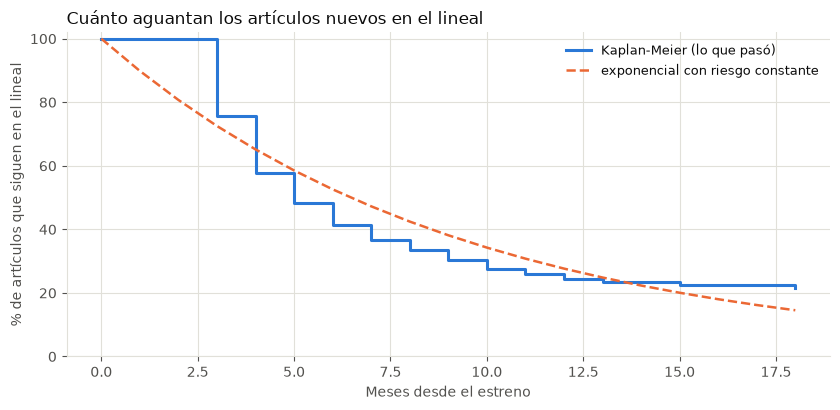

In [21]:
km = sv.kaplan_meier(dur["tiempo"], dur["evento"])
display(km.loc[3:14, ["en_riesgo", "muertes", "riesgo_mes", "supervivencia"]]
        .rename(columns={"muertes": "retirados"}).round(3))

lam = dur["evento"].sum() / dur["tiempo"].sum()   # la exponencial sin reescalar
meses = np.arange(0, km.index.max() + 1)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.step(np.r_[0, km.index], 100 * np.r_[1, km["supervivencia"]], where="post",
        color=AZUL, linewidth=2.2, label="Kaplan-Meier (lo que pasó)")
ax.plot(meses, 100 * np.exp(-lam * meses), color=NARANJA, linestyle="--", linewidth=1.8,
        label="exponencial con riesgo constante")
ax.set_xlabel("Meses desde el estreno")
ax.set_ylabel("% de artículos que siguen en el lineal")
ax.set_ylim(0, 102)
ax.set_title("Cuánto aguantan los artículos nuevos en el lineal", loc="left", fontsize=12, color=TINTA)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
guardar(fig, "kaplan-meier-estrenos")
plt.show()

El riesgo baja con la edad del artículo: en el mes 3, el primero en que la regla
puede saltar, se retira el 24,5 % de los que siguen; en el mes 12, el 5,9 %.
Lo que pasa el filtro de los primeros meses tiende a quedarse: los primeros
meses son los que deciden.

Por eso la exponencial sin más no encaja: a los 6 meses daría 52,6 %
cuando lo real es 41,3 %. La solución es la misma de `rpart`: medir el
tiempo en 'riesgo acumulado' en vez de en meses (sección siguiente).

### 12.2 · El árbol de supervivencia

**Es el mismo tipo de árbol de la sección 7, con otra cosa en las hojas.**
Divide los artículos con preguntas sobre su mes de estreno —las mismas
variables de la sección 3, así que **no hay fuga de datos**—, pero cada hoja,
en vez de decir *«el X % sigue a los 6 meses»*, calcula **un riesgo**:

> riesgo de la hoja = **artículos retirados** / **tiempo total que estuvieron en el lineal**

Con ese riesgo, la curva de supervivencia de la hoja sale de la fórmula de la
exponencial.

**Dos detalles técnicos:**

1. **El tiempo se reescala** con el riesgo acumulado de todo el surtido
   (Nelson-Aalen), porque el riesgo no es constante (12.1). Así cada hoja da un
   **riesgo relativo**: 1 es un artículo medio, 2 se retira al doble de ritmo y
   0,5 a la mitad. Es lo que hace `rpart(method = "exp")` en R.
2. **Contrastado con R.** El árbol se construye en Python
   (`sv.ArbolSupervivencia`) y se ajustó también con `rpart(method = "exp")`
   (`src/supervivencia_rpart.R`). Salen **las mismas preguntas, los mismos
   umbrales y las mismas hojas**; los riesgos difieren en centésimas por una
   pequeña corrección que `rpart` aplica a cada hoja.

Misma profundidad (3) y mismo mínimo por hoja (20 artículos) que el árbol de la
sección 7, para que se pueda leer.

,regla,articulos,mueren,riesgo_relativo,S_3m,S_6m,S_12m,S_6m_real
0,precio ≤ 4.00 y dpto_DROGUERIA Y PERFUMERIA y venta > 5.10,77,26,"0,36","0,92","0,75","0,62","0,77"
1,precio ≤ 4.00 y dpto_DROGUERIA Y PERFUMERIA y venta ≤ 5.10,110,61,"0,70","0,84","0,58","0,41","0,57"
2,precio ≤ 4.00 y no dpto_DROGUERIA Y PERFUMERIA y dpto_ULTRAMARINOS,478,278,"0,73","0,84","0,56","0,39","0,54"
3,precio > 4.00 y unidades > 1.28 y mes_estreno ≤ 9.50,109,79,"1,16","0,75","0,40","0,22","0,33"
4,precio ≤ 4.00 y no dpto_DROGUERIA Y PERFUMERIA y no dpto_ULTRAMARINOS,525,398,"1,23","0,74","0,38","0,20","0,33"
5,precio > 4.00 y unidades ≤ 1.28 y venta > 4.31,144,124,"1,80","0,64","0,24","0,10","0,20"
6,precio > 4.00 y unidades > 1.28 y mes_estreno > 9.50,38,34,"1,84","0,64","0,23","0,09","0,13"
7,precio > 4.00 y unidades ≤ 1.28 y venta ≤ 4.31,28,27,"2,65","0,52","0,12","0,03","0,08"


  guardada 04-curvas-hojas-supervivencia.png / .svg


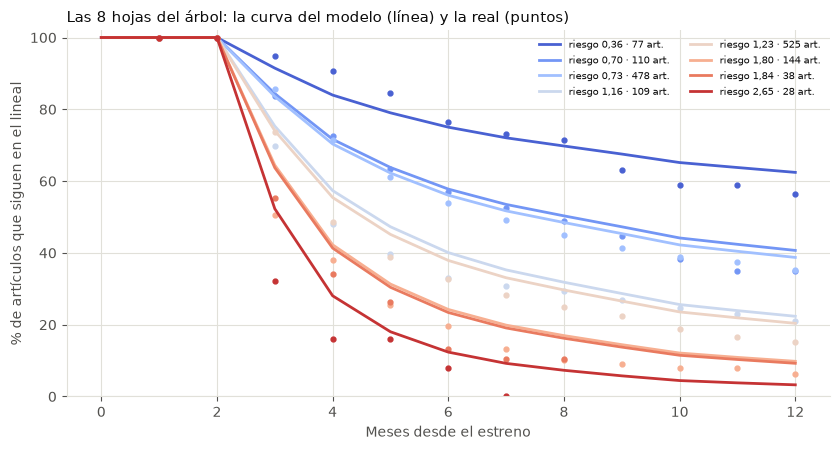

In [22]:
X_dur = sv.matriz_x(dur)
arbol_sv = sv.ArbolSupervivencia().fit(X_dur, dur["tiempo"], dur["evento"])
hojas = sv.hojas_arbol_supervivencia(arbol_sv, X_dur, dur)
with pd.option_context("display.max_colwidth", 90):
    display(hojas.drop(columns="hoja").round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
meses = np.arange(0, 13)
colores = plt.cm.coolwarm(np.linspace(0.05, 0.95, len(hojas)))
en_hoja = arbol_sv.arbol_.apply(X_dur)
for (_, h), color in zip(hojas.iterrows(), colores):
    curva = np.r_[1, np.exp(-h["riesgo_relativo"] * arbol_sv._lambda0(meses[1:]))]
    ax.plot(meses, 100 * curva, color=color, linewidth=2,
            label=f"riesgo {num(h['riesgo_relativo'], 2)} · {h['articulos']} art.")
    km_h = sv.kaplan_meier(dur["tiempo"][en_hoja == h["hoja"]],
                           dur["evento"][en_hoja == h["hoja"]]).loc[:12]
    ax.plot(km_h.index, 100 * km_h["supervivencia"], "o", color=color, markersize=3.5)
ax.set_xlabel("Meses desde el estreno")
ax.set_ylabel("% de artículos que siguen en el lineal")
ax.set_ylim(0, 102)
ax.set_title("Las 8 hojas del árbol: la curva del modelo (línea) y la real (puntos)",
             loc="left", fontsize=11, color=TINTA)
ax.legend(frameon=False, fontsize=7.5, ncol=2)
fig.tight_layout()
guardar(fig, "curvas-hojas-supervivencia")
plt.show()

mejor, peor = hojas.iloc[0], hojas.iloc[-1]
error = (hojas["S_6m"] - hojas["S_6m_real"]).abs()

La mejor hoja: precio ≤ 4.00, droguería y perfumería, y venta > 5.10.
77 artículos. En el lineal: 91 % a los 3 meses, 75 % a los 6, 62 % al año.
La peor: precio > 4.00 y unidades ≤ 1.28 y venta ≤ 4.31.
28 artículos. En el lineal: 52 % a los 3 meses, 12 % a los 6, 3 % al año.

El supuesto se sostiene, con un matiz. La curva del modelo y la real a los 6 meses
se separan como mucho 10,2 puntos, en la mediana 4,5. El matiz: el
modelo es algo optimista en 7 de las 8 hojas (sus puntos caen por
debajo de la línea): en ellas los artículos se retiran todavía más deprisa
al principio de lo que la fórmula supone.

### 12.3 · Los dos árboles, juntos

**Los dos árboles hacen las mismas preguntas sobre las mismas variables**, y
solo cambia lo que dicen al final: el de la sección 7, un sí o un no a los 6
meses; el de supervivencia, la curva entera. Esta celda los pone uno junto al
otro para comprobar si cuentan la misma historia.

In [23]:
from sklearn.tree import export_text

print("Árbol de la sección 7 (sí/no a los 6 meses):\n")
print(export_text(arbol, feature_names=list(X.columns), show_weights=False))
print("Árbol de supervivencia (curva en el tiempo):\n")
print(export_text(arbol_sv.arbol_, feature_names=list(X_dur.columns),
                  show_weights=False, decimals=2))

var_7 = X.columns[arbol.tree_.feature[0]]
var_sv = X_dur.columns[arbol_sv.arbol_.tree_.feature[0]]
umb_7, umb_sv = arbol.tree_.threshold[0], arbol_sv.arbol_.tree_.threshold[0]

Árbol de la sección 7 (sí/no a los 6 meses):

|--- precio <= 4.00
|   |--- venta <= 2.71
|   |   |--- dpto_DROGUERIA Y PERFUMERIA <= 0.50
|   |   |   |--- class: 0
|   |   |--- dpto_DROGUERIA Y PERFUMERIA >  0.50
|   |   |   |--- class: 1
|   |--- venta >  2.71
|   |   |--- dpto_DROGUERIA Y PERFUMERIA <= 0.50
|   |   |   |--- class: 0
|   |   |--- dpto_DROGUERIA Y PERFUMERIA >  0.50
|   |   |   |--- class: 1
|--- precio >  4.00
|   |--- venta <= 10.39
|   |   |--- mes_estreno <= 4.50
|   |   |   |--- class: 0
|   |   |--- mes_estreno >  4.50
|   |   |   |--- class: 0
|   |--- venta >  10.39
|   |   |--- venta <= 12.21
|   |   |   |--- class: 1
|   |   |--- venta >  12.21
|   |   |   |--- class: 0

Árbol de supervivencia (curva en el tiempo):

|--- precio <= 4.00
|   |--- dpto_DROGUERIA Y PERFUMERIA <= 0.50
|   |   |--- dpto_ULTRAMARINOS <= 0.50
|   |   |   |--- value: [1.23]
|   |   |--- dpto_ULTRAMARINOS >  0.50
|   |   |   |--- value: [0.73]
|   |--- dpto_DROGUERIA Y PERFUMERIA >  0.

Primera pregunta: sección 7 'precio ≤ 4,00' · supervivencia 'precio ≤ 4,00'.
La misma pregunta, con el mismo corte: los dos árboles coinciden en lo que
más separa a los artículos que aguantan de los que no.
Y los dos coinciden en el resto de lo importante: la droguería barata
aguanta, y lo caro que vende poco el primer mes cae pronto. El de
supervivencia añade cuándo: la curva mes a mes de cada perfil.

### 12.4 · Comparación de los cuatro modelos

Los cuatro con **la misma etiqueta** (la regla de la tienda) y los mismos 5
pliegues:

- el **árbol de supervivencia** se entrena con **todos** los artículos,
  censurados incluidos;
- la **referencia, la logística y el árbol de la sección 7**, solo con el grupo
  de la sección 1, porque una etiqueta sí/no no admite censura.

Los pliegues no son los de la sección 4 (aquí se reparten 1.509 artículos, no
1.302), así que las cifras se mueven unas milésimas respecto a las de allí.

| Medida | Qué pregunta contesta |
|---|---|
| **AUC a 6 meses** | *¿Sigue en el lineal a los 6 meses?* Sobre el grupo de la sección 1 |
| **Índice C** (Harrell) | *¿Cuál se retira antes?* De cada par de artículos en que se sabe cuál se retiró primero, la proporción en que el modelo le dio más riesgo. Usa también los censurados. 0,5 es el azar |

In [24]:
tabla_sv, riesgos_sv = sv.evaluar_supervivencia(dur)
display(tabla_sv.round(3))

auc = tabla_sv["auc_6m"].drop("baseline")
cidx = tabla_sv["indice_c"].drop("baseline")

print(f"   AUC a 6 meses ... logística {num(auc['logistica'], 3)} · árbol sí/no "
      f"{num(auc['arbol'], 3)} · árbol de supervivencia {num(auc['arbol_supervivencia'], 3)}")
print(f"   índice C ....... logística {num(cidx['logistica'], 3)} · árbol sí/no "
      f"{num(cidx['arbol'], 3)} · árbol de supervivencia {num(cidx['arbol_supervivencia'], 3)}")
print()
dif_auc = auc["arbol_supervivencia"] - auc["arbol"]
dif_c = cidx["arbol_supervivencia"] - cidx["arbol"]

,procedencia,entrena_con,auc_6m,indice_c
modelo,,,,
baseline,DummyClassifier,1302,"0,48","0,48"
logistica,"logística, solo el grupo del modelo de artícul...",1302,"0,70","0,66"
arbol,"CART de clasificación, solo el grupo del model...",1302,"0,65","0,62"
arbol_supervivencia,"CART de supervivencia (rpart 'exp'), con censu...",1509,"0,65","0,62"


   AUC a 6 meses ... logística 0,698 · árbol sí/no 0,649 · árbol de supervivencia 0,650
   índice C ....... logística 0,657 · árbol sí/no 0,625 · árbol de supervivencia 0,624



Gana la logística en las dos medidas.

Árbol contra árbol: la diferencia es de +1 milésimas de AUC y -2 de índice C.
Aciertan prácticamente lo mismo. Lo que gana el árbol de supervivencia no es
precisión, es información: la curva mes a mes, y los artículos censurados.

Y la logística sigue por delante de los dos árboles en ambas medidas, así que
sigue siendo el modelo de artículos nuevos.

### 12.5 · Los siete candidatos de la tienda: si llegan a los 6 meses, y cuándo se decide

La tabla de la sección 11 da, para cada candidato, **la probabilidad de seguir
en el lineal a los 6 meses** (la logística). El árbol de supervivencia la
amplía con **cuándo** se juega esa decisión: la curva de los artículos
históricos del mismo perfil.

Mismas entradas que en la sección 11: precio sin IVA, departamento y, como
son productos que aún no se han vendido, las unidades del primer mes
estimadas por el modelo de volumen (sección 10).

In [25]:
curvas = pd.DataFrame([
    {"producto": c["producto"],
     **sv.curva_producto_nuevo(d, dv, {"departamento": c["departamento"],
                                       "precio": c["precio_con_iva"] / (1 + c["iva"] / 100)},
                               dur=dur, arbol=arbol_sv)}
    for c in candidatos
]).set_index("producto")

tabla_cand = resumen[["prob_sigue_vendiendose_pct"]].rename(
    columns={"prob_sigue_vendiendose_pct": "sigue_a_6_meses_pct (logística)"})
display(tabla_cand.round(0))

perfiles = curvas["hoja"].unique()
for hoja in perfiles:
    c = curvas[curvas["hoja"] == hoja].iloc[0]
    print(f"\nPerfil del árbol de supervivencia: {c['regla']}")
    print(f"({c['articulos_perfil']} artículos históricos) — "
          f"{', '.join(curvas.index[curvas['hoja'] == hoja])}")
    print(f"   siguen en el lineal: {num(100 * c['S_3m'], 0)} % a los 3 meses · "
          f"{num(100 * c['S_6m'], 0)} % a los 6 · {num(100 * c['S_12m'], 0)} % al año")

,sigue_a_6_meses_pct (logística)
producto,
Claras de huevo pasteurizadas 1L,"69,00"
Hamburguesa vegetal/vegana congelada,"30,00"
Nata para cocinar sin lactosa (200 ml),"44,00"
Masa de pizza sin gluten,"28,00"
Payés harina sostenible,"30,00"
Barra gallega,"33,00"
Campera nature,"31,00"



Perfil del árbol de supervivencia: precio ≤ 4.00 y no dpto_DROGUERIA Y PERFUMERIA y no dpto_ULTRAMARINOS
(525 artículos históricos) — Claras de huevo pasteurizadas 1L, Hamburguesa vegetal/vegana congelada, Nata para cocinar sin lactosa (200 ml), Masa de pizza sin gluten, Payés harina sostenible, Barra gallega, Campera nature
   siguen en el lineal: 74 % a los 3 meses · 38 % a los 6 · 20 % al año


Los 7 candidatos caen en el mismo perfil: el árbol de supervivencia no los
ordena entre sí (eso lo hace la logística, arriba), pero dice cuándo se
decide: del 74 % a los 3 meses al 38 % a los 6. Si la tienda mete
alguno, los meses 3 a 6 son los que hay que vigilar.

### 12.6 · Conclusiones de la sección

**Una sola historia con los dos árboles.** El de la sección 7 dice *si* un
artículo nuevo seguirá en el lineal a los 6 meses; el de supervivencia dice
además *cómo va cayendo* mes a mes. Hacen la misma primera pregunta, coinciden
en lo importante y aciertan casi lo mismo: el segundo **amplía** al primero,
no lo corrige. La curva de Kaplan-Meier añade algo que ninguno daba solo:
**los primeros meses son los que deciden**, también para los siete candidatos
de la tienda.

**Sin fuga de datos por variables que cambian con el tiempo.** Todas las
variables se toman con su valor del mes de estreno. Con un matiz: el dato es
mensual, así que una oferta que empieza el día 25 en un artículo estrenado el
día 20 cuenta como «de inicio».

**Ampliaciones posibles:** Weibull AFT, regresión de Cox y Random Survival
Forest.